
Best parameters selected by KKT merit:
eta1                     2.000000
eta2                     2.000000
base_step                2.000000
final_kkt_merit          0.000159
final_primal_dual_gap    0.000040
Name: 0, dtype: float64


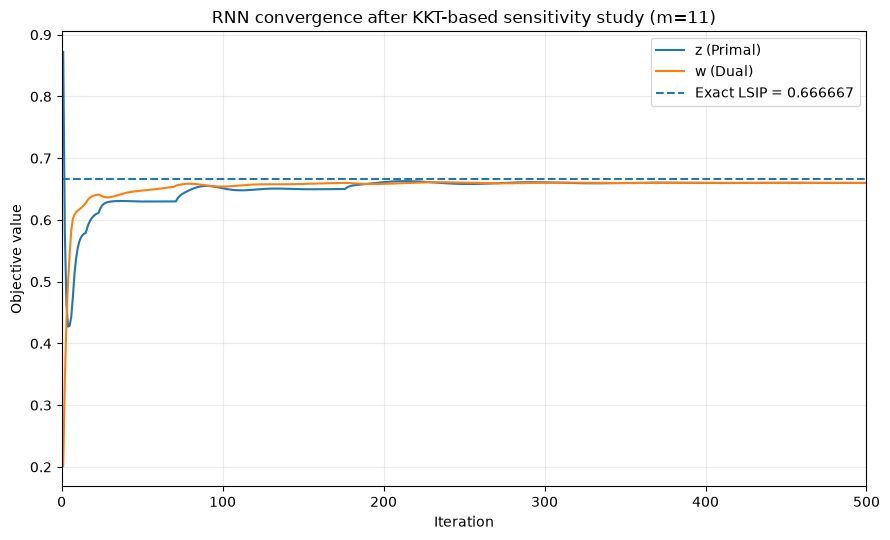


Tuned 500-iteration results:
    m  eta1  eta2  base_step  integration_step  iterations  final_x1  final_x2  final_objective  final_objective_error_posthoc  final_dense_max_violation  final_primal_dual_gap  final_kkt_merit  best_kkt_iteration  best_kkt_merit  runtime_sec
   11   2.0   2.0        2.0          0.852803         500  0.119468  0.420994         0.659930                       0.006737                   0.002498               0.000040         0.000159                 500        0.000159     0.048698
  101   2.0   2.0        2.0          0.281439         500  0.106751  0.450239         0.663741                       0.002925                   0.001001               0.001348         0.002805                 341        0.002606     0.045673
 1001   2.0   2.0        2.0          0.089398         500  0.110634  0.443996         0.665263                       0.001403                   0.000468               0.000597         0.001101                 146        0.000934     0.05454

In [4]:
"""
RNN parameter-sensitivity experiment for LSIP Example 1.

Important:
- Uses the existing paper-equation implementation.
- Runs exactly 500 iterations.
- Chooses parameters by KKT merit, not by matching the known optimum.
- Analytical objective error is reported only after selection as validation.
"""

from pathlib import Path
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

BASE_FILE = Path("RNN_semi_infinite_paper_with_plots.py")

spec = importlib.util.spec_from_file_location("rnn_base", BASE_FILE)
rnn = importlib.util.module_from_spec(spec)
spec.loader.exec_module(rnn)

def run_fixed_500(m, eta1, eta2, base_step, x0=(0.5,0.5), y0=0.0, iterations=500):
    _, A, B = rnn.build_constraints(m)
    x = np.array(x0, dtype=np.float64)
    y = np.full(m, y0, dtype=np.float64)

    spectral_norm = float(np.linalg.norm(A, ord=2))
    step = base_step / max(1.0, spectral_norm)

    best = None
    history = []
    started = time.perf_counter()

    for iteration in range(1, iterations + 1):
        dx, dy = rnn._paper_rnn_derivatives(x, y, A, B, eta1, eta2)
        x = np.maximum(0.0, x + step * dx)
        y = np.maximum(0.0, y + step * dy)

        met = rnn._metrics(x, y, A, B)

        if not (
            np.all(np.isfinite(x))
            and np.all(np.isfinite(y))
            and np.isfinite(met["kkt_merit"])
        ):
            return None, None

        if best is None or met["kkt_merit"] < best["kkt_merit"]:
            best = {"iteration": iteration, **met}

        history.append({
            "iteration": iteration,
            "z": abs(float(met["primal_z"])),
            "w": abs(float(met["dual_w"])),
            "objective": float(met["objective"]),
            "primal_dual_gap": float(met["primal_dual_gap"]),
            "grid_max_violation": float(met["grid_max_violation"]),
            "dual_max_violation": float(met["dual_max_violation"]),
            "kkt_merit": float(met["kkt_merit"]),
        })

    runtime = time.perf_counter() - started
    dense_v, worst_t = rnn.dense_constraint_check(x)
    final = rnn._metrics(x, y, A, B)

    return {
        "m": m,
        "eta1": eta1,
        "eta2": eta2,
        "base_step": base_step,
        "integration_step": step,
        "iterations": iterations,
        "final_x1": float(x[0]),
        "final_x2": float(x[1]),
        "final_objective": float(final["objective"]),
        "final_objective_error_posthoc": abs(float(final["objective"]) - rnn.F_EXACT),
        "final_dense_max_violation": dense_v,
        "final_primal_dual_gap": float(final["primal_dual_gap"]),
        "final_kkt_merit": float(final["kkt_merit"]),
        "best_kkt_iteration": int(best["iteration"]),
        "best_kkt_merit": float(best["kkt_merit"]),
        "runtime_sec": runtime,
    }, pd.DataFrame(history)

eta_values = [0.02, 0.05, 0.10, 0.20, 0.50, 1.0, 2.0]
base_steps = [0.10, 0.20, 0.50, 1.0, 2.0]

rows = []
for eta1 in eta_values:
    for eta2 in eta_values:
        for base_step in base_steps:
            result, _ = run_fixed_500(11, eta1, eta2, base_step)
            if result is not None:
                rows.append(result)

df = pd.DataFrame(rows).sort_values(
    ["final_kkt_merit", "final_primal_dual_gap"]
).reset_index(drop=True)

best = df.iloc[0]
print("\nBest parameters selected by KKT merit:")
print(best[["eta1","eta2","base_step","final_kkt_merit","final_primal_dual_gap"]])

out = Path.cwd() / "results"
out.mkdir(exist_ok=True)

df.to_csv(out / "rnn_parameter_sensitivity_500.csv", index=False)

all_results = []
all_history = []

for m in [11,101,1001,10001]:
    result, hist = run_fixed_500(
        m,
        float(best.eta1),
        float(best.eta2),
        float(best.base_step),
    )
    all_results.append(result)
    hist["m"] = m
    all_history.append(hist)

results_df = pd.DataFrame(all_results)
history_df = pd.concat(all_history, ignore_index=True)

results_df.to_csv(out / "rnn_tuned_500_results.csv", index=False)
history_df.to_csv(out / "rnn_tuned_500_history.csv", index=False)

m11 = history_df[history_df["m"] == 11]

plt.figure(figsize=(9,5.5))
plt.plot(m11["iteration"], m11["z"], label="z (Primal)")
plt.plot(m11["iteration"], m11["w"], label="w (Dual)")
plt.axhline(rnn.F_EXACT, linestyle="--", label="Exact LSIP = 0.666667")
plt.xlabel("Iteration")
plt.ylabel("Objective value")
plt.title("RNN convergence after KKT-based sensitivity study (m=11)")
plt.xlim(0,500)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(out / "rnn_tuned_z_w_m11.png", dpi=200, bbox_inches="tight")
plt.show()

print("\nTuned 500-iteration results:")
print(results_df.to_string(index=False))
